In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("My Uber Drives - 2016.csv")

df = df[df["START_DATE*"] != "Totals"]

df["START_DATE*"] = pd.to_datetime(df["START_DATE*"], errors="coerce")
df = df.dropna(subset=["START_DATE*"])

df["Hour"] = df["START_DATE*"].dt.hour
df["Day"] = df["START_DATE*"].dt.dayofweek
df["Month"] = df["START_DATE*"].dt.month

df = df.dropna(subset=["MILES*"])
X = df[["Hour", "Day", "Month"]]
y = df["MILES*"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("R² Score :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))

R² Score : 0.019308294425338435
MAE : 9.948899581612306


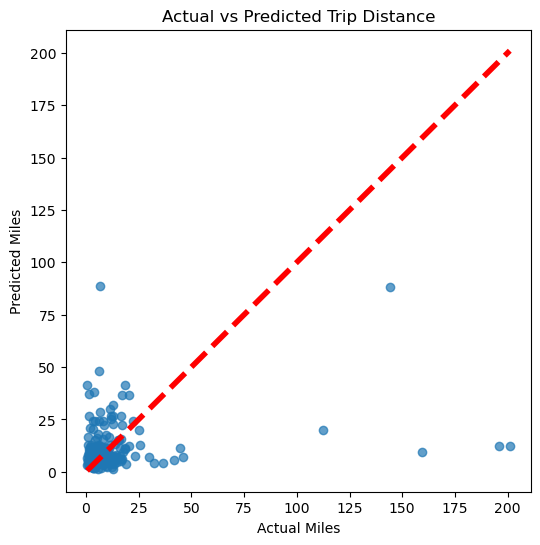

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red',
         linestyle='--',
         linewidth=4)
plt.xlabel("Actual Miles")
plt.ylabel("Predicted Miles")
plt.title("Actual vs Predicted Trip Distance")
plt.show()